
First 5 rows:
   S.NO       Player Name Nation Code Nationality Category  BWF Rank 2026  \
0     1    Viktor Axelsen     Denmark         DEN       MS              2   
1     2          Shi Yuqi       China         CHN       MS              1   
2     3       Lee Zii Jia    Malaysia         MAS       MS              3   
3     4  Jonatan Christie   Indonesia         INA       MS              5   
4     5      Kento Momota       Japan         JPN       MS              7   

   Highest Rank Ever  Ranking points  Age  Height(cm)  ... Stamina Index  \
0                  1          108900   30         194  ...            85   
1                  1          112300   28         182  ...            88   
2                  2           97400   26         178  ...            82   
3                  3           85200   26         176  ...            84   
4                  1           74500   29         176  ...            83   

   Net Play Score  Matches 2024  Wins 2024  Losses 2024  Win Loss

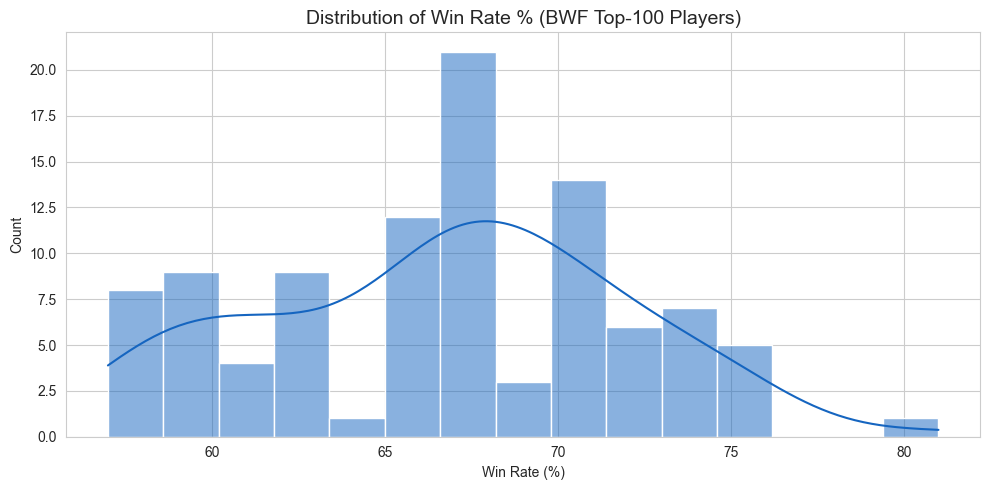

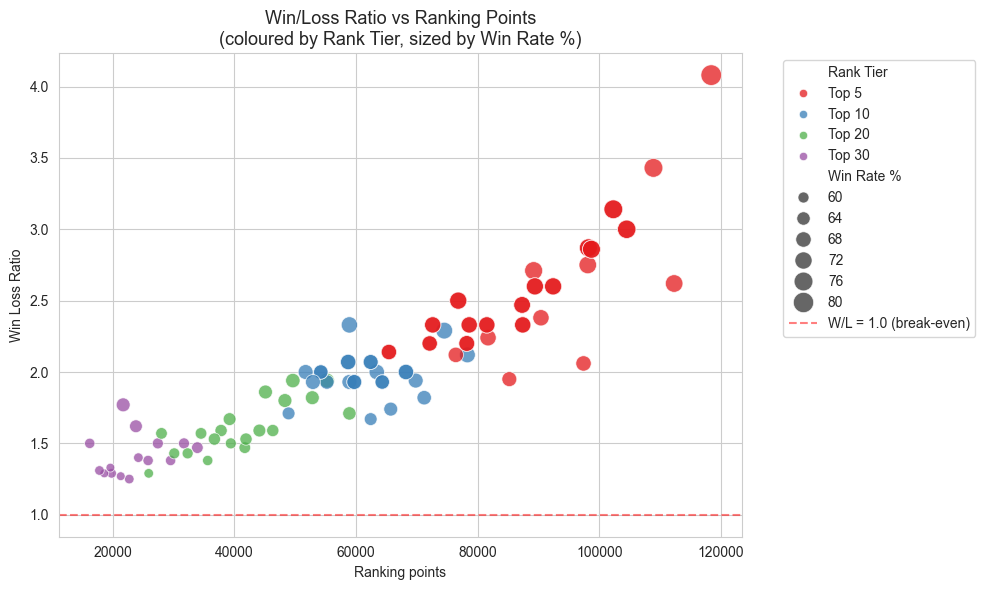

winloss vs ranking


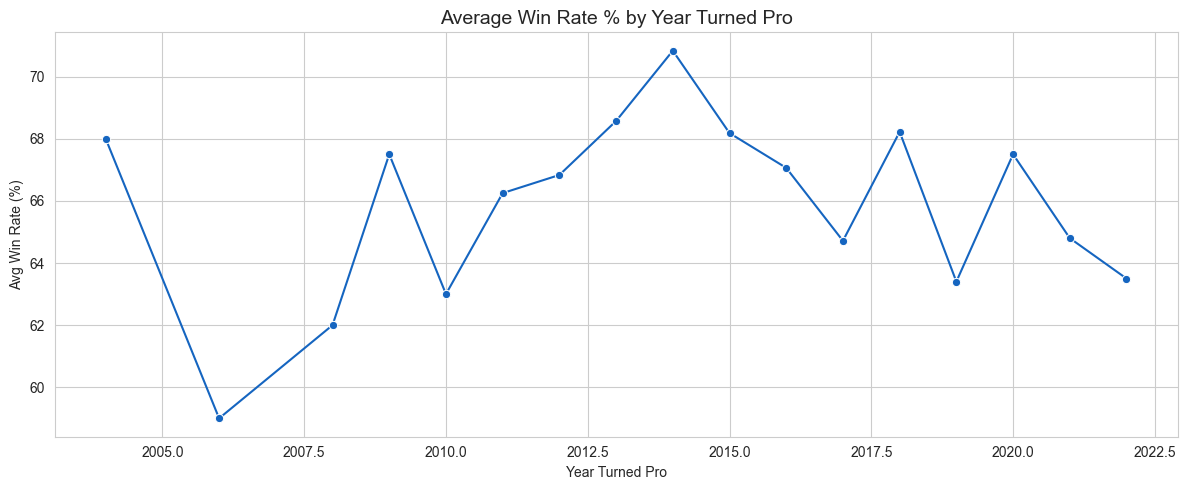

winrate by year pro


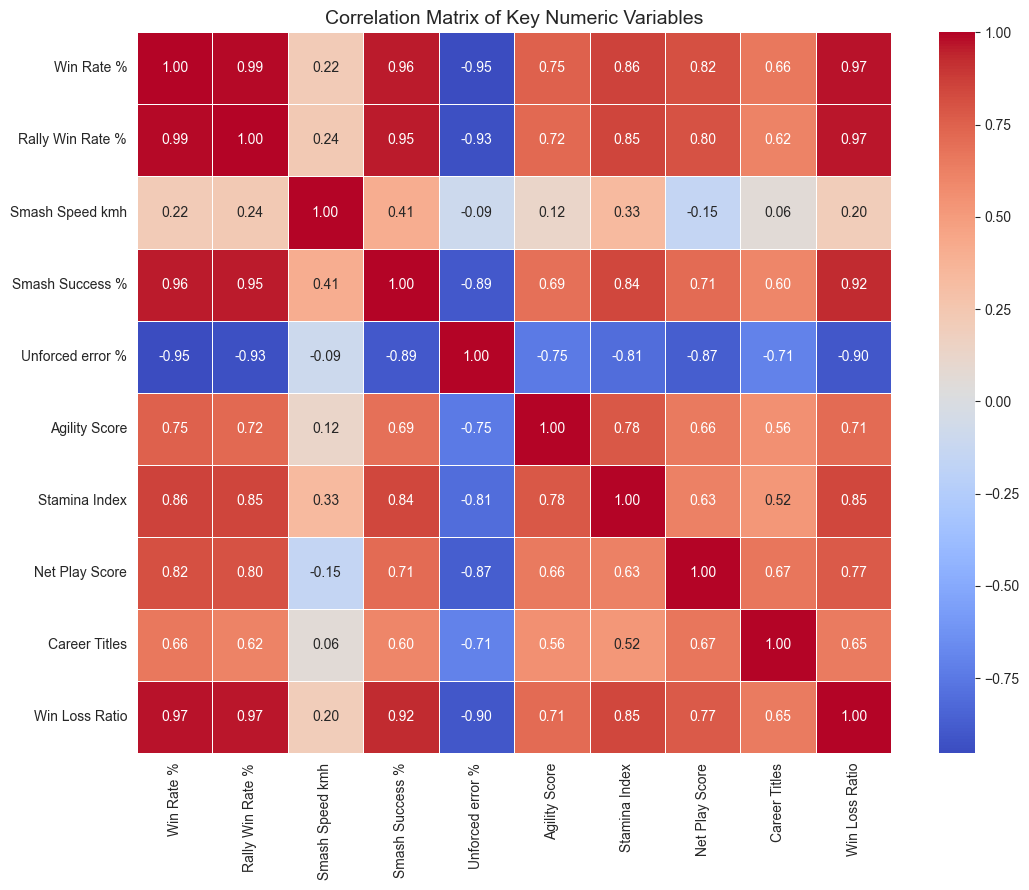

correlation heatmap


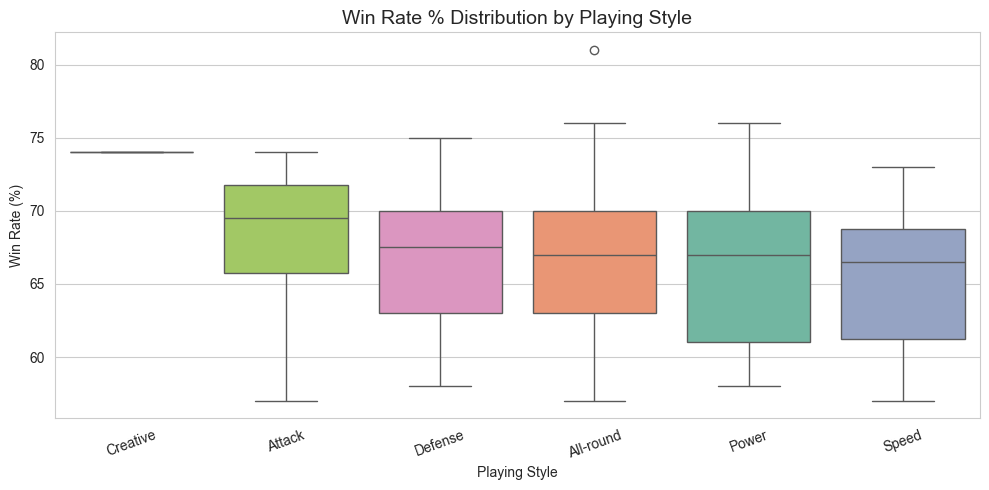

winrate by style


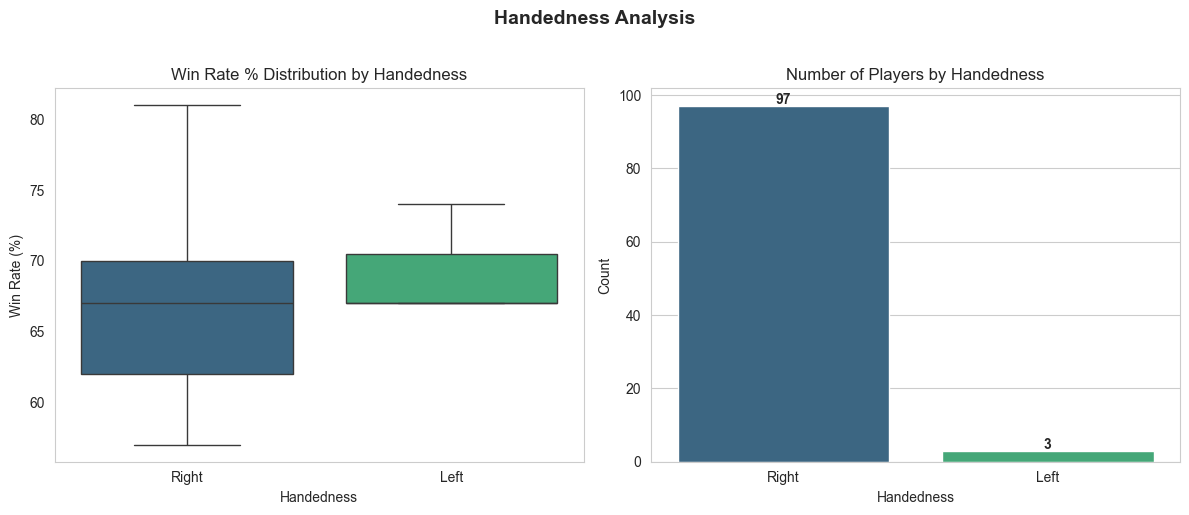

handedness


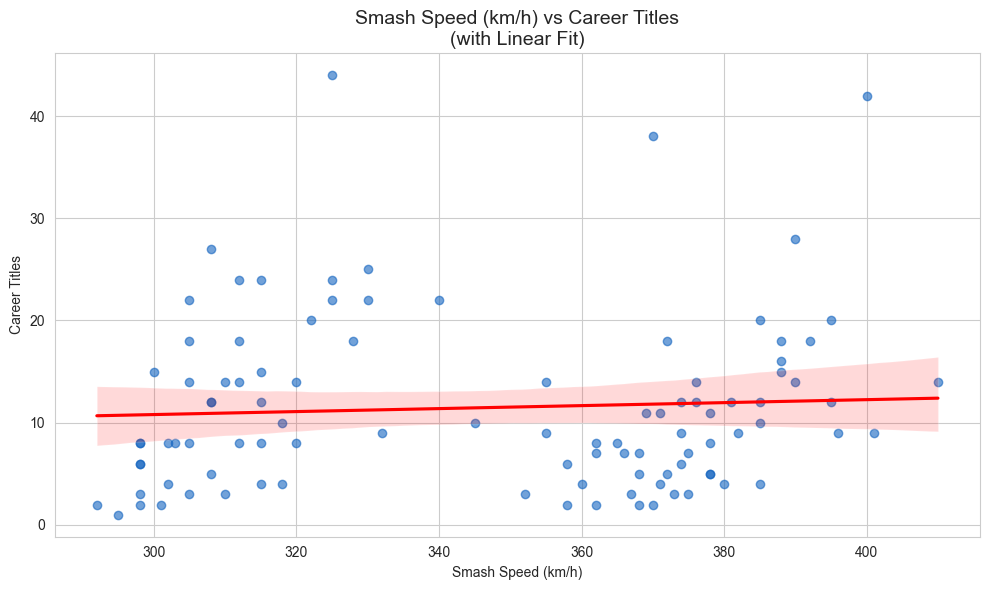

smashspeed vs titles


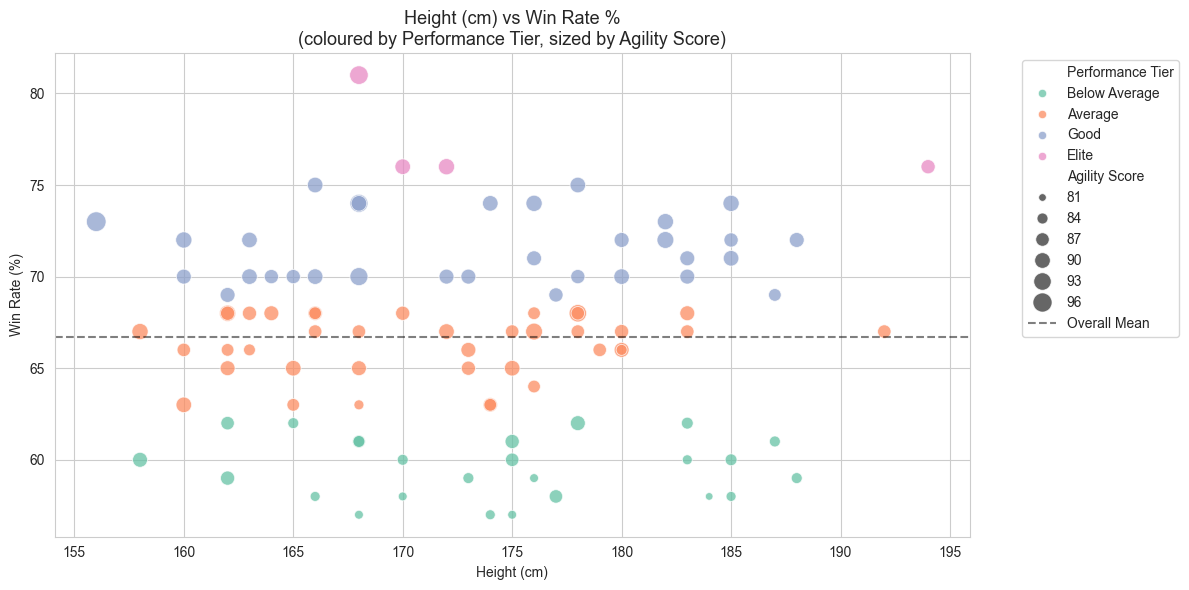

height vs winrate


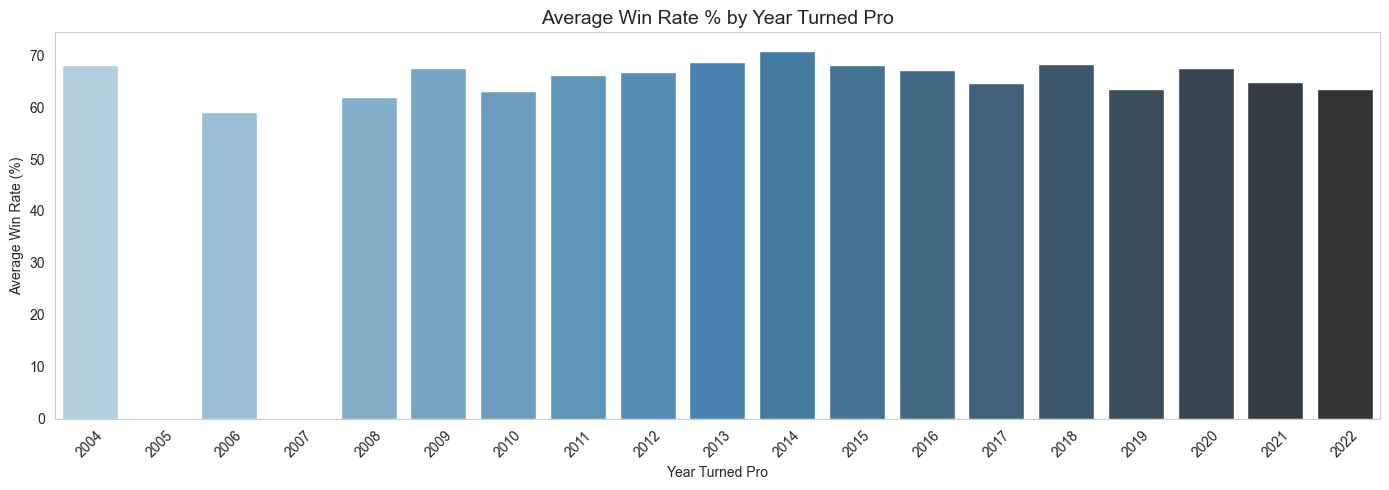

winrate by year


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
df = pd.read_csv(r"C:\Users\prana\Downloads\Badminton_Dataset_CLEANED.csv")
df.columns = df.columns.str.strip() 
print("\nFirst 5 rows:")
print(df.head())
print("\nColumn info:")
df.info()
numeric_cols = [
    "BWF Rank 2026", "Highest Rank Ever", "Ranking points", "Age",
    "Height(cm)", "Career Titles", "Win Rate %", "Rally Win Rate %",
    "Smash Speed kmh", "Smash Success %", "Unforced error %",
    "Agility Score", "Stamina Index", "Net Play Score",
    "Matches 2024", "Wins 2024", "Losses 2024", "Win Loss Ratio",
    "Year Turned Pro", "Years Active",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print("\nMissing values per column:")
print(df.isnull().sum())
df_clean = df.dropna(subset=["Win Rate %", "Win Loss Ratio", "Ranking points"])
print(f"\nAfter dropping missing key columns: {df_clean.shape[0]} rows remain.")
df_clean = df_clean.copy()
df_clean["Performance Tier"] = pd.cut(
    df_clean["Win Rate %"],
    bins=[0, 62, 68, 75, 100],
    labels=["Below Average", "Average", "Good", "Elite"],
)
df_clean["Rank Tier"] = pd.cut(
    df_clean["BWF Rank 2026"],
    bins=[0, 5, 10, 20, 30],
    labels=["Top 5", "Top 10", "Top 20", "Top 30"],
)
df_model = df_clean.copy()
#EDA
print("\n" + "="*50)
print("EDA: STATISTICAL SUMMARIES")
print("="*50)
print("\nSummary statistics for key performance metrics:")
print(df_clean[["Win Rate %", "Rally Win Rate %", "Smash Speed kmh",
                "Career Titles", "Agility Score", "Stamina Index"]].describe())
print("\nAverage Win Rate % by Category:")
print(df_clean.groupby("Category", observed=True)["Win Rate %"].mean()
      .sort_values(ascending=False))
print("\nAverage Win Rate % by Rank Tier:")
print(df_clean.groupby("Rank Tier", observed=True)["Win Rate %"].mean()
      .sort_values(ascending=False))
print("\nTop 10 players by Win Rate %:")
top10 = df_clean.nlargest(10, "Win Rate %")[
    ["Player Name", "Win Rate %", "Career Titles"]
]
print(top10.to_string(index=False))
#STATIC VISUALISATIONS
#Distribution of Win Rate %
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["Win Rate %"], bins=15, kde=True, color="#1565C0")
plt.title("Distribution of Win Rate % (BWF Top-100 Players)", fontsize=14)
plt.xlabel("Win Rate (%)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("plot_01_winrate_distribution.png", dpi=150)
plt.show()
#Win Loss Ratio vs Ranking Points
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="Ranking points", y="Win Loss Ratio",
    hue="Rank Tier", size="Win Rate %",
    sizes=(40, 220), alpha=0.75,
    palette="Set1",
)
plt.axhline(y=1.0, color="red", linestyle="--", alpha=0.5, label="W/L = 1.0 (break-even)")
plt.title("Win/Loss Ratio vs Ranking Points\n(coloured by Rank Tier, sized by Win Rate %)", fontsize=13)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("plot_02_winloss_vs_ranking.png", dpi=150)
plt.show()
print("winloss vs ranking")
#Average Win Rate % over Year Turned Pro
yearly_wr = (df_clean.groupby("Year Turned Pro")["Win Rate %"]
             .mean().reset_index())
plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly_wr, x="Year Turned Pro", y="Win Rate %", marker="o", color="#1565C0")
plt.title("Average Win Rate % by Year Turned Pro", fontsize=14)
plt.xlabel("Year Turned Pro")
plt.ylabel("Avg Win Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_03_winrate_by_year_pro.png", dpi=150)
plt.show()
print("winrate by year pro")
#Correlation Heatmap
heat_cols = [
    "Win Rate %", "Rally Win Rate %", "Smash Speed kmh",
    "Smash Success %", "Unforced error %", "Agility Score",
    "Stamina Index", "Net Play Score", "Career Titles",
    "Win Loss Ratio",
]
corr = df_clean[heat_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Key Numeric Variables", fontsize=14)
plt.tight_layout()
plt.savefig("plot_04_correlation_heatmap.png", dpi=150)
plt.show()
print("correlation heatmap")
#Win Rate % by Playing Style
style_order = (df_clean.groupby("Playing style")["Win Rate %"]
               .median().sort_values(ascending=False).index.tolist())
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x="Playing style", y="Win Rate %",
            order=style_order, hue="Playing style", palette="Set2", legend=False)
plt.title("Win Rate % Distribution by Playing Style", fontsize=14)
plt.xlabel("Playing Style")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("plot_05_winrate_by_style.png", dpi=150)
plt.show()
print("winrate by style")
#Win Rate % by Handedness + Count
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_clean, x="Handedness", y="Win Rate %",
            order=["Right", "Left"], hue="Handedness", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Win Rate % Distribution by Handedness")
axes[0].set_xlabel("Handedness")
axes[0].set_ylabel("Win Rate (%)")
axes[0].grid(axis="y")
hand_counts = df_clean["Handedness"].value_counts()
sns.barplot(x=hand_counts.index, y=hand_counts.values,
            hue=hand_counts.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Number of Players by Handedness")
axes[1].set_ylabel("Count")
for bar, val in zip(axes[1].patches, hand_counts.values):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.5, str(val),
                 ha="center", fontweight="bold")
plt.suptitle("Handedness Analysis", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("plot_06_handedness.png", dpi=150)
plt.show()
print("handedness")
#Smash Speed vs Career Titles with regression
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_clean,
    x="Smash Speed kmh", y="Career Titles",
    scatter_kws={"alpha": 0.6, "color": "#1565C0"},
    line_kws={"color": "red"},
)
plt.title("Smash Speed (km/h) vs Career Titles\n(with Linear Fit)", fontsize=14)
plt.xlabel("Smash Speed (km/h)")
plt.ylabel("Career Titles")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_07_smashspeed_vs_titles.png", dpi=150)
plt.show()
print("smashspeed vs titles")
#Height vs Win Rate %
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_clean,
    x="Height(cm)", y="Win Rate %",
    hue="Performance Tier",
    size="Agility Score",
    sizes=(30, 200),
    palette="Set2",
    alpha=0.75,
)
plt.title("Height (cm) vs Win Rate %\n(coloured by Performance Tier, sized by Agility Score)", fontsize=13)
plt.xlabel("Height (cm)")
plt.ylabel("Win Rate (%)")
plt.axhline(y=df_clean["Win Rate %"].mean(), color="black",
            linestyle="--", alpha=0.5, label="Overall Mean")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("plot_08_height_vs_winrate.png", dpi=150)
plt.show()
print("height vs winrate")
#Average Win Rate % by Year Turned Pro
all_years = pd.DataFrame({"Year Turned Pro": range(
    int(df_clean["Year Turned Pro"].min()),
    int(df_clean["Year Turned Pro"].max()) + 1
)})
yearly_bar = (all_years
              .merge(yearly_wr, on="Year Turned Pro", how="left")
              .fillna(0))
plt.figure(figsize=(14, 5))
sns.barplot(data=yearly_bar, x="Year Turned Pro", y="Win Rate %",
            hue="Year Turned Pro", palette="Blues_d", legend=False)
plt.title("Average Win Rate % by Year Turned Pro", fontsize=14)
plt.xlabel("Year Turned Pro")
plt.ylabel("Average Win Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("plot_09_winrate_bar_by_year.png", dpi=150)
plt.show()
print("winrate by year")


